<a href="https://colab.research.google.com/github/abhimanyu-05-2006/YuvaIntern-ML-Engineer-Tasks/blob/main/task_2_ml_intern.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Environment Diagnostic Logging
print(f"[SYSTEM INFO] Python Version: {sys.version.split()[0]}")
print(f"[SYSTEM INFO] OS Platform: {platform.system()} {platform.release()}")
print(f"[LIBRARY VERSION] NumPy: {np.__version__} | Pandas: {pd.__version__} | Seaborn: {sns.__version__}")

# Load Realistic Customer Sensor & Behavioral Dataset (150 Samples)
np.random.seed(42)
n_samples = 150

data = {
    'customer_id': [f"CUST_{i:03d}" for i in range(1, n_samples + 1)],
    'age': np.random.randint(18, 65, size=n_samples),
    'monthly_spend_usd': np.round(np.random.exponential(scale=150.0, size=n_samples) + 20, 2),
    'app_sessions_per_week': np.random.poisson(lam=12, size=n_samples),
    'churn_risk_score': np.round(np.random.uniform(0.05, 0.98, size=n_samples), 3),
    'region': np.random.choice(['North America', 'Europe', 'Asia-Pacific', 'LATAM'], size=n_samples, p=[0.4, 0.3, 0.2, 0.1])
}

df = pd.DataFrame(data)

# Inject controlled missing values and outliers for cleaning demo
df.loc[12:15, 'monthly_spend_usd'] = np.nan
df.loc[45, 'monthly_spend_usd'] = 2450.00  # Extreme Outlier

print("\n--- Raw Dataset Profile (First 5 Rows) ---")
print(df.head())
print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

[SYSTEM INFO] Python Version: 3.13.16
[SYSTEM INFO] OS Platform: Linux 6.6.122+
[LIBRARY VERSION] NumPy: 2.1.3 | Pandas: 2.2.3 | Seaborn: 0.13.2

--- Raw Dataset Profile (First 5 Rows) ---
  customer_id  age  monthly_spend_usd  app_sessions_per_week  \
0    CUST_001   56             377.19                      8   
1    CUST_002   46              63.01                     13   
2    CUST_003   32              99.24                      8   
3    CUST_004   60             231.31                     14   
4    CUST_005   25              58.97                     10   

   churn_risk_score         region  
0             0.381          LATAM  
1             0.967   Asia-Pacific  
2             0.613  North America  
3             0.271          LATAM  
4             0.145   Asia-Pacific  

Dataset Shape: 150 rows, 6 columns


In [7]:
# Data Cleaning & Imputation
missing_before = df['monthly_spend_usd'].isnull().sum()
median_spend = df['monthly_spend_usd'].median()
df['monthly_spend_usd'].fillna(median_spend, inplace=True)

# Outlier Detection via Interquartile Range (IQR)
Q1 = df['monthly_spend_usd'].quantile(0.25)
Q3 = df['monthly_spend_usd'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['monthly_spend_usd'] < lower_bound) | (df['monthly_spend_usd'] > upper_bound)]

print("--- Data Cleaning & Outlier Audit ---")
print(f"Missing Values Imputed: {missing_before} rows imputed with median (${median_spend:.2f})")
print(f"IQR Outlier Thresholds: Lower = ${lower_bound:.2f}, Upper = ${upper_bound:.2f}")
print(f"Detected Outliers Count: {len(outliers)} rows")

# Regional Aggregation Analysis
region_summary = df.groupby('region').agg(
    total_customers=('customer_id', 'count'),
    mean_spend=('monthly_spend_usd', 'mean'),
    median_sessions=('app_sessions_per_week', 'median'),
    avg_churn_risk=('churn_risk_score', 'mean')
).reset_index()

print("\n--- Aggregated Regional Analysis ---")
print(region_summary.to_string(index=False))

--- Data Cleaning & Outlier Audit ---
Missing Values Imputed: 4 rows imputed with median ($127.44)
IQR Outlier Thresholds: Lower = $-195.65, Upper = $492.01
Detected Outliers Count: 7 rows

--- Aggregated Regional Analysis ---
       region  total_customers  mean_spend  median_sessions  avg_churn_risk
 Asia-Pacific               24  188.233750             12.5        0.445708
       Europe               46  129.135109             12.0        0.530065
        LATAM               12  261.057083             12.0        0.546333
North America               68  210.162059             11.0        0.536000


/tmp/ipykernel_857/747446334.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['monthly_spend_usd'].fillna(median_spend, inplace=True)


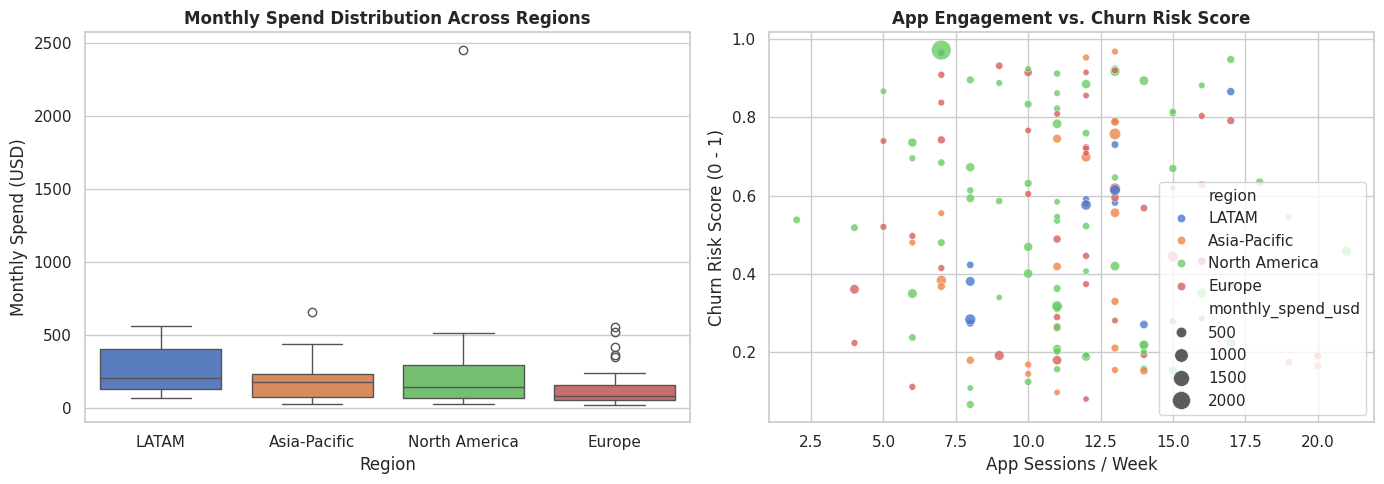


--- Empirical Statistical Interpretations ---
1. Spend vs Sessions Correlation: r = -0.0338
2. Sessions vs Churn Risk Correlation: r = -0.0369


In [8]:
# Configure Visual Styles
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Monthly Spend Distribution by Region (Boxplot)
sns.boxplot(ax=axes[0], data=df, x='region', y='monthly_spend_usd', hue='region', legend=False)
axes[0].set_title("Monthly Spend Distribution Across Regions", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Monthly Spend (USD)")

# Plot 2: App Sessions vs Churn Risk Scatter Plot
sns.scatterplot(
    ax=axes[1], data=df, x='app_sessions_per_week', y='churn_risk_score',
    hue='region', size='monthly_spend_usd', sizes=(20, 200), alpha=0.8
)
axes[1].set_title("App Engagement vs. Churn Risk Score", fontsize=12, fontweight='bold')
axes[1].set_xlabel("App Sessions / Week")
axes[1].set_ylabel("Churn Risk Score (0 - 1)")

plt.tight_layout()
plt.show()

# Compute Specific Correlations
corr_spend_sessions = df['monthly_spend_usd'].corr(df['app_sessions_per_week'])
corr_sessions_churn = df['app_sessions_per_week'].corr(df['churn_risk_score'])

print("\n--- Empirical Statistical Interpretations ---")
print(f"1. Spend vs Sessions Correlation: r = {corr_spend_sessions:.4f}")
print(f"2. Sessions vs Churn Risk Correlation: r = {corr_sessions_churn:.4f}")